# Multi-antenna baseband KLT pipeline

Parametric pipeline to generate multi-antenna GUPPI raw baseband data with
`setigen`, read it back, run the MR-KLT per frequency channel, and score the
result against the injected ground truth.

Each generated scenario is paired with a `.meta.json` sidecar holding the
signals that were planted, so the analysis can be *checked* rather than merely
inspected.

**Structure.** The scenario generation/loading machinery lives in
[`helpers.py`](helpers.py); the per-channel MR-KLT sweep is
`seti_klt.scan_channels`, shared with the real-data notebook in
[`../Meerkat_Real_Data/`](../Meerkat_Real_Data/). This notebook is only the
orchestration, so it stays readable.

Generated `.raw` scenarios go to `outputs/raw_data/`, figures to
`outputs/figures/`, and the run log to `outputs/logs/` — all git-ignored.

## 1. Setup & configuration

In [3]:
%load_ext autoreload
%autoreload 2

# Optional GPU acceleration for setigen (requires the [gpu] extra: cupy).
# Must be set BEFORE setigen is imported, hence before `import helpers`.
ENABLE_GPU = True
if ENABLE_GPU:
    import os
    os.environ["SETIGEN_ENABLE_GPU"] = "1"
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import numpy as np
import matplotlib.pyplot as plt

from seti_klt import scan_channels
from seti_klt.utils.io import (
    SimpleLogger,
    LogLevel,
    prepare_output_dir,
    save_figure,
)

import helpers

np.random.seed(42)

# Logger: console + outputs/logs/maa_pipeline.log
logger = SimpleLogger(level=LogLevel.INFO, filename="maa_pipeline.log")
logger.section("Multi-Antenna KLT Pipeline Initialization")

# Generated scenarios (.raw + .meta.json) live under outputs/raw_data
SCENARIO_DIR = prepare_output_dir("outputs/raw_data")

# Analysis parameters
POLARIZATION     = 0
N_SAMPLES        = 3072     # timesteps (K) loaded per scenario
EXCLUDE_CHANNELS = {0}      # DC channel; add band edges if needed, e.g. {0, 63}
KN_ALPHA         = 0.01     # Kritchman-Nadler false-alarm rate (percentage points)

logger.summary_stats({
    "Scenario dir":      str(SCENARIO_DIR),
    "Polarization":      POLARIZATION,
    "Samples (K)":       N_SAMPLES,
    "Excluded channels": sorted(EXCLUDE_CHANNELS),
    "KN alpha (%)":      KN_ALPHA,
}, title="Pipeline Configuration")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Logging to: /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/MAA_Simulated/outputs/logs/maa_pipeline.log

=== MULTI-ANTENNA KLT PIPELINE INITIALIZATION

=== PIPELINE CONFIGURATION
[15:20:50] [INFO]     Scenario dir: outputs/raw_data
[15:20:50] [INFO]     Polarization: 0
[15:20:50] [INFO]     Samples (K): 3072
[15:20:50] [INFO]     Excluded channels: [0]
[15:20:50] [INFO]     KN alpha (%): 0.0100


## 2. Define & generate scenarios

A signal is a dict with:

- `kind`: `"coherent"` (sky signal — injected on the background streams, so it receives
  the geometric delays and is coherent across **all** antennas) or `"per_antenna"`
  (RFI / local signal — on a subset of antennas, **without** delays, hence spatially
  incoherent).
- `channel`: recorded coarse channel to place it in (`0..num_chans-1`). Alternatively
  pass `f_start_hz` directly.
- `drift_rate`: Hz/s. `level`: amplitude.
- `per_antenna` only: `n_antennas` (how many, chosen at random) **or** `antenna_indices`
  (exactly which ones).

See `helpers.generate_scenario` for the full parameter list.

In [4]:
logger.section("Scenario Generation")

SCENARIOS = {
    # A: a single coherent sky signal
    "scen_A": dict(
        num_antennas=60,
        signals=[{"kind": "coherent", "channel": 20, "drift_rate": 15, "level": 0.05}],
    ),
    # B: RFI on all antennas + coherent target (the "classic" case)
    "scen_B": dict(
        num_antennas=60,
        signals=[
            {"kind": "per_antenna", "channel": 10, "drift_rate": 0,  "level": 0.1},   # RFI, all antennas
            {"kind": "coherent",    "channel": 20, "drift_rate": 15, "level": 0.05},  # target
        ],
    ),
    # C: signal seen by only 20 of 60 antennas (partial coverage)
    "scen_C": dict(
        num_antennas=60,
        signals=[
            {"kind": "per_antenna", "channel": 30, "drift_rate": 5, "level": 0.08, "n_antennas": 20},
        ],
    ),
    # D: three signals in different channels, mixed cases
    "scen_D": dict(
        num_antennas=80,
        signals=[
            {"kind": "per_antenna", "channel": 8,  "drift_rate": 0,  "level": 0.12, "n_antennas": 80},  # strong RFI
            {"kind": "coherent",    "channel": 25, "drift_rate": 12, "level": 0.05},                    # target A
            {"kind": "coherent",    "channel": 45, "drift_rate": -8, "level": 0.03},                    # weak target B
        ],
    ),
}

# Trim this list (or set it to []) to skip scenarios you already have on disk.
TO_GENERATE = ["scen_A", "scen_B", "scen_C", "scen_D"]

for name in TO_GENERATE:
    helpers.generate_scenario(
        name, output_dir=SCENARIO_DIR, logger=logger, **SCENARIOS[name]
    )


=== SCENARIO GENERATION
[15:21:02] [INFO]     [scen_A] 60 antennas | delay range: -840.8 .. 821.5 ns (4986 samples).
[15:21:02] [INFO]       + signal 0: coherent    ch=20 level=0.05 -> ALL
[15:21:02] [INFO]       writing (8192 samp/block x 1 blocks)...
[15:22:07] [INFO]       OK wrote outputs/raw_data/scen_A.0000.raw + scen_A.meta.json
[15:22:07] [INFO]     [scen_B] 60 antennas | delay range: -849.3 .. 829.8 ns (5037 samples).
[15:22:07] [INFO]       + signal 0: per_antenna ch=10 level=0.1 -> ALL
[15:22:07] [INFO]       + signal 1: coherent    ch=20 level=0.05 -> ALL
[15:22:07] [INFO]       writing (8192 samp/block x 1 blocks)...
[15:23:12] [INFO]       OK wrote outputs/raw_data/scen_B.0000.raw + scen_B.meta.json
[15:23:12] [INFO]     [scen_C] 60 antennas | delay range: -857.9 .. 838.2 ns (5089 samples).
[15:23:13] [INFO]       + signal 0: per_antenna ch=30 level=0.08 -> 20 ant
[15:23:13] [INFO]       writing (8192 samp/block x 1 blocks)...
[15:24:18] [INFO]       OK wrote outputs/raw

## 3. Load a scenario

In [5]:
logger.section("Loading Scenario")

SCENARIO = "scen_B"

data, meta = helpers.load_scenario(
    SCENARIO_DIR / SCENARIO,
    pol=POLARIZATION,
    n_samples=N_SAMPLES,
    logger=logger,
)
truth = helpers.signal_channels(meta)

K, N_CHANNELS, N_A = data.shape   # (realisations, channels, antennas)

logger.summary_stats({
    "Scenario":              SCENARIO,
    "Realisations (K)":      K,
    "Channels (F)":          N_CHANNELS,
    "Antennas (N_A)":        N_A,
    "gamma = N_A/(K-1)":     round(N_A / (K - 1), 4),
    "Ground-truth channels": truth,
}, title=f"Scenario {SCENARIO}")


=== LOADING SCENARIO
[15:25:55] [INFO]     [scen_B] data (3072, 64, 60) | signal channels (ground truth): [10, 20]

=== SCENARIO SCEN_B
[15:25:55] [INFO]     Scenario: scen_B
[15:25:55] [INFO]     Realisations (K): 3072
[15:25:55] [INFO]     Channels (F): 64
[15:25:55] [INFO]     Antennas (N_A): 60
[15:25:55] [INFO]     gamma = N_A/(K-1): 0.0195
[15:25:55] [INFO]     Ground-truth channels: [10, 20]


## 4. Per-channel MR-KLT sweep

`seti_klt.scan_channels` runs, for every frequency channel: the MR-KLT on the
`(K, N_A)` antenna slice, the Kritchman-Nadler rank estimate on the resulting
eigenspectrum, and a reconstruction keeping exactly that many eigenvectors.
The DC channel is excluded.

The full eigenspectrum of every channel is retained (not just the dominant
eigenvalue), so it can be plotted as a heatmap further down.

In [6]:
logger.section("Per-Channel MR-KLT Sweep")

scan = scan_channels(
    data,
    exclude_channels=EXCLUDE_CHANNELS,
    alpha=KN_ALPHA,
    beta=2,                      # complex (I/Q) baseband
)

# Score the detection against the injected ground truth
detected  = scan.detected_channels()
missed    = [c for c in truth if scan.k_est[c] == 0]
false_pos = [c for c in detected if c not in truth]

for c in truth:
    logger.info(f"channel {c}: expected signal -> K_est = {scan.k_est[c]}")

logger.summary_stats({
    "Ground truth":    truth,
    "Detected":        detected,
    "Missed":          missed or "none",
    "False positives": false_pos or "none",
}, title="Detection vs Ground Truth")


=== PER-CHANNEL MR-KLT SWEEP
[15:26:14] [INFO]     channel 10: expected signal -> K_est = 1
[15:26:14] [INFO]     channel 20: expected signal -> K_est = 1

=== DETECTION VS GROUND TRUTH
[15:26:14] [INFO]     Ground truth: [10, 20]
[15:26:14] [INFO]     Detected: [10, 20]
[15:26:14] [INFO]     Missed: none
[15:26:14] [INFO]     False positives: none


## 5. Waterfall & PSD


=== WATERFALL AND PSD
Figure saved → /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/MAA_Simulated/outputs/figures/scen_B_waterfall.png


/tmp/ipykernel_71216/2900214796.py:34: RuntimeWarning: Mean of empty slice
  psd_recon = np.nanmean(power_recon, axis=0)


Figure saved → /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/MAA_Simulated/outputs/figures/scen_B_psd_comparison.png


PosixPath('/mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/MAA_Simulated/outputs/figures/scen_B_psd_comparison.png')

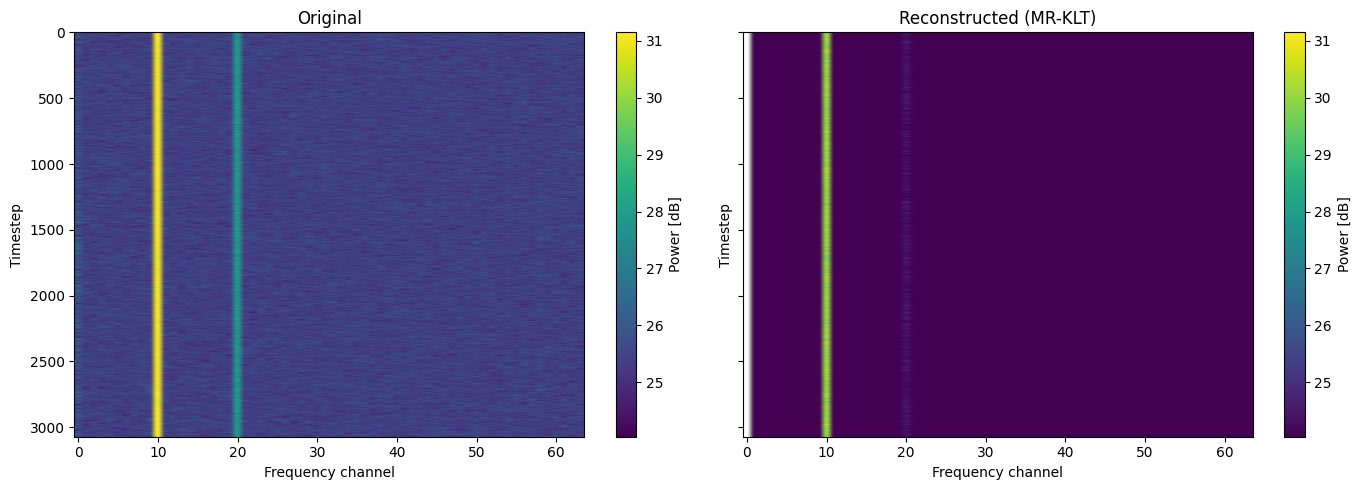

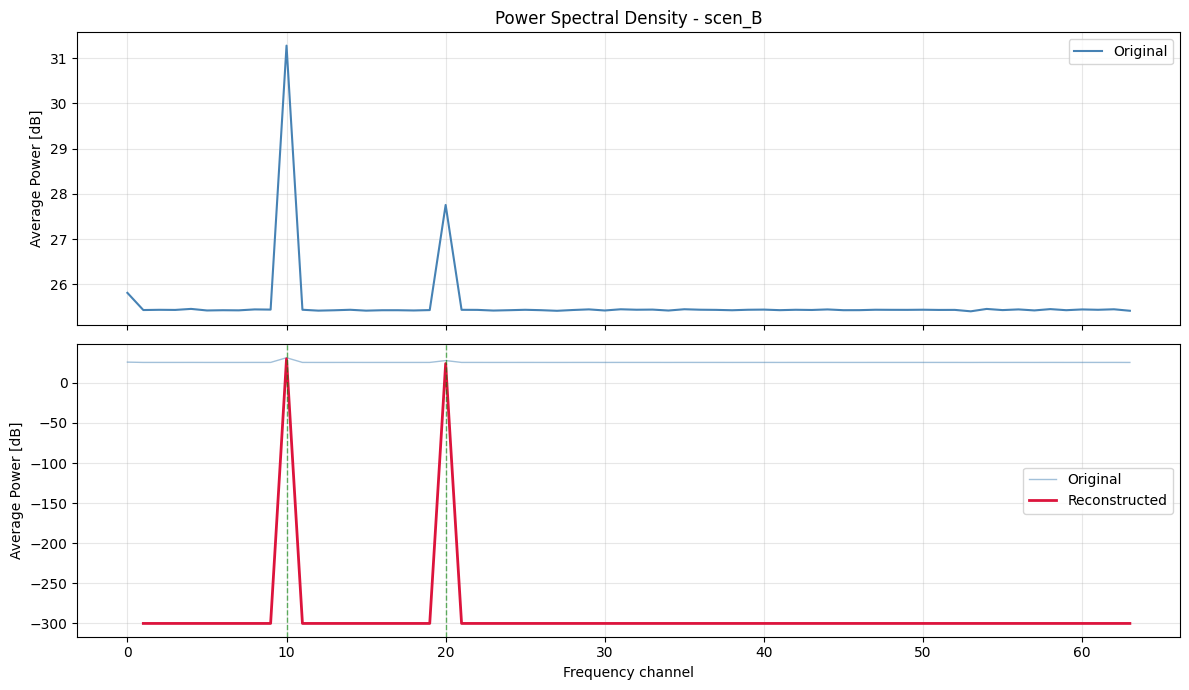

In [9]:
%matplotlib inline

logger.section("Waterfall and PSD")

power_orig  = scan.power_orig     # (K, F)
power_recon = scan.power_recon    # (K, F), NaN on excluded channels

# --- WATERFALL ---
logp = 10 * np.log10(power_orig + 1e-30)
logp[:, sorted(EXCLUDE_CHANNELS)] = np.nan     # hide the DC channel in the Original too
vmin = float(np.nanpercentile(logp, 1))
vmax = float(np.nanpercentile(logp, 99))

fig_wf, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, power, title in [
    (axes[0], power_orig,  "Original"),
    (axes[1], power_recon, "Reconstructed (MR-KLT)"),
]:
    im = ax.imshow(
        10 * np.log10(power + 1e-30),
        aspect="auto", cmap="viridis", origin="upper",
        vmin=vmin, vmax=vmax,
        extent=[-0.5, N_CHANNELS - 0.5, K - 0.5, -0.5],
    )
    ax.set_xlabel("Frequency channel")
    ax.set_ylabel("Timestep")
    ax.set_title(title)
    fig_wf.colorbar(im, ax=ax, label="Power [dB]")
fig_wf.tight_layout()
save_figure(fig_wf, filename=f"{SCENARIO}_waterfall.png")

# --- PSD ---
psd_orig  = np.nanmean(power_orig,  axis=0)
psd_recon = np.nanmean(power_recon, axis=0)

fig_psd, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(range(N_CHANNELS), 10 * np.log10(psd_orig + 1e-30),
             color="steelblue", lw=1.5, label="Original")
axes[0].set_ylabel("Average Power [dB]")
axes[0].set_title(f"Power Spectral Density - {SCENARIO}")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(range(N_CHANNELS), 10 * np.log10(psd_orig + 1e-30),
             color="steelblue", lw=1, alpha=0.5, label="Original")
axes[1].plot(range(N_CHANNELS), 10 * np.log10(psd_recon + 1e-30),
             color="crimson",   lw=2,            label="Reconstructed")
for c in truth:
    axes[1].axvline(c, color="green", ls="--", lw=1, alpha=0.6)
axes[1].set_xlabel("Frequency channel")
axes[1].set_ylabel("Average Power [dB]")
axes[1].legend(); axes[1].grid(alpha=0.3)
fig_psd.tight_layout()
save_figure(fig_psd, filename=f"{SCENARIO}_psd_comparison.png")

## 6. Eigenvalue heatmap & rank per channel

Bottom panel: the full eigenspectrum of every channel, each normalised by its own
noise floor (median eigenvalue) so channels with different absolute scales are
comparable. A bright bottom row (index 0) means a dominant eigenvalue, i.e.
inter-antenna coherence in that channel.

Top panel: `K_est` per channel — how many eigenvalues the Kritchman-Nadler
estimator kept. Dashed lines mark the injected ground-truth channels.


=== EIGENVALUE HEATMAP AND RANK PER CHANNEL
Figure saved → /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/MAA_Simulated/outputs/figures/scen_B_eigenvalue_heatmap.png


PosixPath('/mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/MAA_Simulated/outputs/figures/scen_B_eigenvalue_heatmap.png')

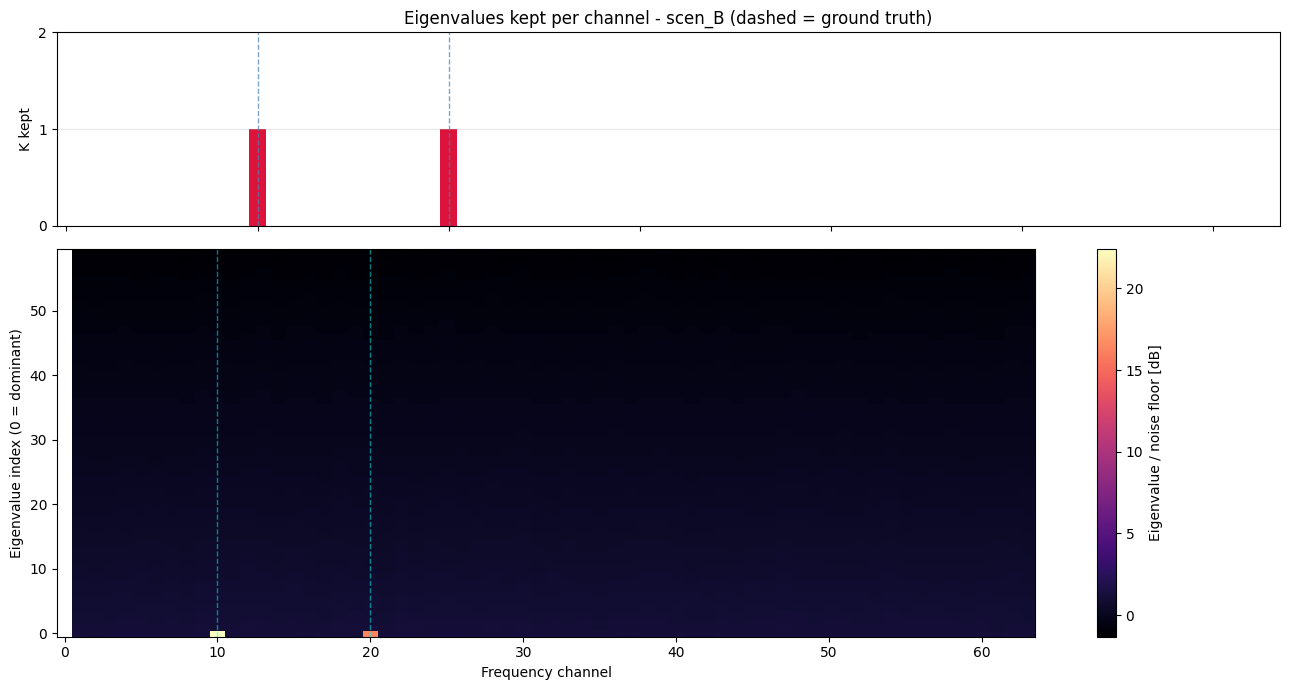

In [10]:
logger.section("Eigenvalue Heatmap and Rank per Channel")

evals_norm = scan.noise_normalised_eigenvalues()   # (F, N_A), in units of the noise floor

fig_hm, (ax0, ax1) = plt.subplots(
    2, 1, figsize=(13, 7), sharex=True,
    gridspec_kw={"height_ratios": [1, 2]},
)

# Top: number of eigenvalues kept per channel
ax0.bar(range(N_CHANNELS), scan.k_est, color="crimson", width=0.9)
ax0.set_ylabel("K kept")
ax0.set_title(f"Eigenvalues kept per channel - {SCENARIO} (dashed = ground truth)")
ax0.grid(alpha=0.3, axis="y")
ax0.set_yticks(range(0, int(scan.k_est.max()) + 2))

# Bottom: full eigenspectrum of every channel as a heatmap
im = ax1.imshow(
    10 * np.log10(evals_norm.T + 1e-12),          # dB relative to the noise floor
    aspect="auto", origin="lower", cmap="magma",
    extent=[-0.5, N_CHANNELS - 0.5, -0.5, N_A - 0.5],
)
ax1.set_xlabel("Frequency channel")
ax1.set_ylabel("Eigenvalue index (0 = dominant)")
fig_hm.colorbar(im, ax=ax1, label="Eigenvalue / noise floor [dB]")

for c in truth:
    ax0.axvline(c, color="steelblue", ls="--", lw=1, alpha=0.7)
    ax1.axvline(c, color="cyan",      ls="--", lw=1, alpha=0.5)

fig_hm.tight_layout()
save_figure(fig_hm, filename=f"{SCENARIO}_eigenvalue_heatmap.png")

## 7. Single-channel eigenspectrum

Detailed eigenspectrum for the channel with the strongest dominant eigenvalue.


=== SINGLE-CHANNEL EIGENSPECTRUM
[15:28:15] [INFO]     Strongest channel: 10 | lambda1 = 59950.6002 | K_est = 1
Figure saved → /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/MAA_Simulated/outputs/figures/scen_B_ch10_eigenspectrum.png
[15:28:15] [INFO]     Pipeline executed successfully. All assets saved locally.
Log closed: /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/MAA_Simulated/outputs/logs/maa_pipeline.log


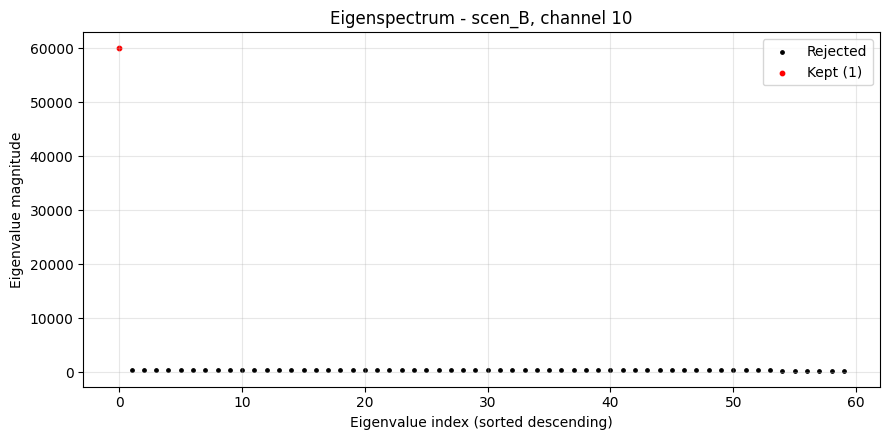

In [11]:
logger.section("Single-Channel Eigenspectrum")

FREQ_CH = int(np.nanargmax(scan.lambda1))
evals   = scan.eigenvalues[FREQ_CH]
n_kept  = int(scan.k_est[FREQ_CH])

logger.info(
    f"Strongest channel: {FREQ_CH} | lambda1 = {scan.lambda1[FREQ_CH]:.4f} | "
    f"K_est = {n_kept}"
)

fig_spec, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(range(n_kept, len(evals)), evals[n_kept:],
           color="black", s=6,  label="Rejected")
ax.scatter(range(n_kept), evals[:n_kept],
           color="red",   s=10, label=f"Kept ({n_kept})")
ax.set_xlabel("Eigenvalue index (sorted descending)")
ax.set_ylabel("Eigenvalue magnitude")
ax.set_title(f"Eigenspectrum - {SCENARIO}, channel {FREQ_CH}")
ax.legend(); ax.grid(alpha=0.3)
fig_spec.tight_layout()
save_figure(fig_spec, filename=f"{SCENARIO}_ch{FREQ_CH}_eigenspectrum.png")

logger.info("Pipeline executed successfully. All assets saved locally.")
logger.close()